# APID 11 exploration

APID 11 has only 132 packets, 130 of them 24 bytes. Like APID 14 and APID 8 it looks like a command target whose downlink holds the PUS
telecommand verification reports. Questions:

1. Is it only reports? Any data?
2. When were commands sent, and does the list of commands have a structure?
3. Anything about the Sun, SWAP or LYRA?

In [1]:
from collections import Counter, defaultdict
from datetime import UTC, datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt

from cadu import iter_packets, packet_apid

In [2]:
CADU_DIR = Path("cadus")
APID = 11

GPS_EPOCH = datetime(1980, 1, 6, tzinfo=UTC)
GPS_MINUS_TICK = 1_209_613_891  # GPS seconds minus tick, from APID_0.ipynb / APID_18.ipynb

# A report is 24 bytes, as in APID 14 and APID 8: primary header, `10 01 <subtype>`, marker `00 01`, tick (4 bytes) and
# fraction (2 bytes), `00`, the request id of the telecommand (packet id and sequence control) and a CRC-16.
REPORT_LEN = 24
SUBTYPE_OFFSET = 8
TIME_OFFSET = 11
FRACTION_OFFSET = 15
REQUEST_OFFSET = 18
CRC_LEN = 2
ACCEPTED = 1
COMPLETED = 7
TELECOMMAND_ID = 0x180B  # version 0, type 1 (telecommand), secondary header, APID 11

## 1. Load

In [3]:
packets: list[tuple[str, int, bytes]] = []  # (file name, vcid, packet)
for path in sorted(CADU_DIR.glob("*.cadu")):
    packets += [(path.name, vcid, packet) for vcid, packet in iter_packets(path) if packet_apid(packet) == APID]

print(f"{len(packets)} packets with APID {APID}")
print("per file:", dict(Counter(name for name, _, _ in packets)))
print("per virtual channel:", dict(Counter(vcid for _, vcid, _ in packets)))
print("lengths:", Counter(len(packet) for _, _, packet in packets))
print("secondary headers of the 24 byte ones:", Counter(p[6:9].hex() for _, _, p in packets if len(p) == REPORT_LEN))

132 packets with APID 11
per file: {'proba2_dump(1).cadu': 28, 'proba2_dump(10).cadu': 36, 'proba2_dump(5).cadu': 1, 'proba2_dump(6).cadu': 33, 'proba2_dump(8).cadu': 33, 'proba2_dump_aug_12_eclipse.cadu': 1}
per virtual channel: {1: 50, 2: 81, 3: 1}
lengths: Counter({24: 130, 8658: 1, 223: 1})
secondary headers of the 24 byte ones: Counter({'100101': 65, '100107': 65})


## 2. Reports and debris

130 of the 132 are 24 bytes with `10 01 01` (accepted) or `10 01 07` (completed): PUS service 1, as in APID 14. The other two
are debris (a packet of 8 658 bytes in dump 5 with a corrupted id and one of 223 bytes in dump 8).

In [4]:
def crc16(data: bytes) -> int:
    """CRC-16/CCITT-FALSE."""
    crc = 0xFFFF
    for byte in data:
        crc ^= byte << 8
        for _ in range(8):
            crc = ((crc << 1) ^ 0x1021) & 0xFFFF if crc & 0x8000 else (crc << 1) & 0xFFFF
    return crc


def tick_of(packet: bytes) -> float:
    return int.from_bytes(packet[TIME_OFFSET : TIME_OFFSET + 4]) + int.from_bytes(packet[FRACTION_OFFSET:][:2]) / 65536


def utc(tick: float) -> datetime:
    return GPS_EPOCH + timedelta(seconds=tick + GPS_MINUS_TICK)


def request_count(packet: bytes) -> int:
    return int.from_bytes(packet[REQUEST_OFFSET + 2 : REQUEST_OFFSET + 4]) & 0x3FFF


for name, vcid, packet in packets:
    if len(packet) != REPORT_LEN:
        print(f"debris: {name} vc {vcid} {len(packet)} bytes {packet[:16].hex(' ')}")

reports = [(n, v, p) for n, v, p in packets if len(p) == REPORT_LEN]
ok = [crc16(p[:-CRC_LEN]) == int.from_bytes(p[-CRC_LEN:]) for _, _, p in reports]
print(f"{len(reports)} reports, CRC ok in {sum(ok)}")
reports = [r for r, good in zip(reports, ok, strict=True) if good]
print("request packet ids:", Counter(p[REQUEST_OFFSET : REQUEST_OFFSET + 2].hex() for _, _, p in reports))
print("request sequence flags:", Counter(p[REQUEST_OFFSET + 2] >> 6 for _, _, p in reports))
print("subtypes:", Counter(p[SUBTYPE_OFFSET] for _, _, p in reports))

debris: proba2_dump(5).cadu vc 3 8658 bytes 48 0b a9 71 84 5a d3 68 c8 5d ae cb 06 0a 5b 00
debris: proba2_dump(8).cadu vc 2 223 bytes 20 0b ee a0 00 d8 40 0c 64 00 04 36 cb 21 cc 45
130 reports, CRC ok in 129
request packet ids: Counter({'180b': 129})
request sequence flags: Counter({3: 129})
subtypes: Counter({1: 65, 7: 64})


Every report is about a telecommand packet `0x180b`: type 1, secondary header, **APID 11**, unsegmented. So APID 11 is a command target with its own
14 bit counter, and this APID in the downlink holds the answers. There is nothing but reports: no data, no events.

## 3. The commands

In [5]:
commands: dict[tuple[str, int], dict[int, float]] = defaultdict(dict)  # (file, count) -> subtype -> tick
for name, _, packet in reports:
    commands[name, request_count(packet)][packet[SUBTYPE_OFFSET]] = tick_of(packet)
print(len(commands), "commands, subtypes per command:", Counter(tuple(sorted(c)) for c in commands.values()))

by_file = defaultdict(dict)  # file -> count -> {subtype: tick}
for (name, count), item in commands.items():
    by_file[name][count] = item
print()
print(f"{'file':22s} {'commands':>8s}  {'counts':>11s}  first command (UTC)      last")
for name, items in sorted(by_file.items(), key=lambda kv: min(min(c.values()) for c in kv[1].values())):
    times = [t for c in items.values() for t in c.values()]
    print(
        f"{name:22s} {len(items):8d}  {min(items):5d}-{max(items):5d}  "
        f"{utc(min(times)):%a %Y-%m-%d %H:%M:%S}  {utc(max(times)):%H:%M:%S}"
    )

67 commands, subtypes per command: Counter({(1, 7): 62, (1,): 3, (7,): 2})

file                   commands       counts  first command (UTC)      last
proba2_dump(10).cadu         18    949- 1000  Thu 2025-08-14 15:04:37  16:55:31
proba2_dump(8).cadu          17   1087- 1244  Sun 2025-08-17 02:24:05  03:58:10
proba2_dump(6).cadu          17   1027- 1100  Tue 2025-08-19 02:16:37  03:51:24
proba2_dump(1).cadu          15   2565- 2614  Thu 2025-10-09 11:34:54  16:43:46


Four dumps hold APID 11 commands (10, 8, 6 and 1), on Thursday 2025-08-14, Sunday 08-17, Tuesday 08-19 and Thursday 2025-10-09, 15 to 18 commands each (a
stray report each in dump 5 and in the eclipse dump are the debris). The counter is its own: 949-1000 (August 14), 1 087-1 244 (August 17), 1 027-1 100
(August 19) and 2 565-2 614 (October 9): about 20 a day in August, then a jump of over 1 300 in the weeks to October 9 (APID 8's counter was reset
instead).

### Acceptance and completion are *not* a millisecond apart here

In APID 14 and APID 8 the 1/7 comes about a millisecond after the 1/1. Here:

In [6]:
for name, items in sorted(by_file.items(), key=lambda kv: min(min(c.values()) for c in kv[1].values())):
    first = min(items)
    start = min(t for c in items.values() for t in c.values())
    print(name)
    for count in sorted(items):
        accepted = items[count].get(ACCEPTED)
        done = items[count].get(COMPLETED)
        text = f"accepted +{accepted - start:7.0f} s" if accepted is not None else "accepted    lost  "
        text += f"  completed +{done - start:7.0f} s" if done is not None else "  completed    lost"
        if accepted is not None and done is not None:
            text += f"  took {done - accepted:5.1f} s"
        print(f"  count +{count - first:3d} {text}")

proba2_dump(10).cadu
  count +  0 accepted +      0 s  completed +      1 s  took   1.0 s
  count +  1 accepted +      5 s  completed +      5 s  took   0.0 s
  count +  2 accepted +     10 s  completed +     25 s  took  14.8 s
  count +  3 accepted +     25 s  completed +     32 s  took   7.4 s
  count +  4 accepted +     32 s  completed +     75 s  took  42.6 s
  count +  5 accepted +     75 s  completed +     87 s  took  12.0 s
  count +  6 accepted +     87 s  completed +     89 s  took   2.2 s
  count +  7 accepted +     89 s  completed +     97 s  took   7.7 s
  count +  8 accepted +   6560 s  completed +   6561 s  took   1.0 s
  count +  9 accepted +   6565 s  completed +   6565 s  took   0.0 s
  count + 10 accepted +   6570 s  completed +   6585 s  took  14.8 s
  count + 11 accepted +   6585 s  completed +   6591 s  took   6.4 s
  count + 12 accepted +   6591 s  completed +   6630 s  took  39.3 s
  count + 13 accepted +   6630 s  completed +   6643 s  took  12.1 s
  count + 14 

A command takes **0 to 49 s** to complete, and the next one is accepted right when the previous one completes (command +2 completes at +25 s, +3 is
accepted at +25 s). So these are not single commands sent from the ground one by one: they are the **steps of a stored procedure**, run by an on-board
interpreter, in which each step is accepted when the one before it has finished.

The durations are the same in all four dumps, step by step: about 1, 0, 15, 7, 40-49, 12-14, 2-8 and 8-15 s for the steps +0 to +7 (a pause, a wait, a long
operation: what the steps are is not in the downlink). The counts +8 to +15 are the **second half of the same procedure**: the counter continues, and the durations
are the same again (1, 0, 15, 7, 38-46, 12-13, 2, 7-41 s), but it starts 1.5 to 5 hours after the first half (5 555-18 499 s), so there was a long wait or a
time tag between steps +7 and +8. Between the halves, 900 s and 905 s after the first report, come two more commands whose count is higher by 36 to 156: a later upload that
was run first. The reports that are missing (5 of 134 possible) are lost frames or fail the CRC.

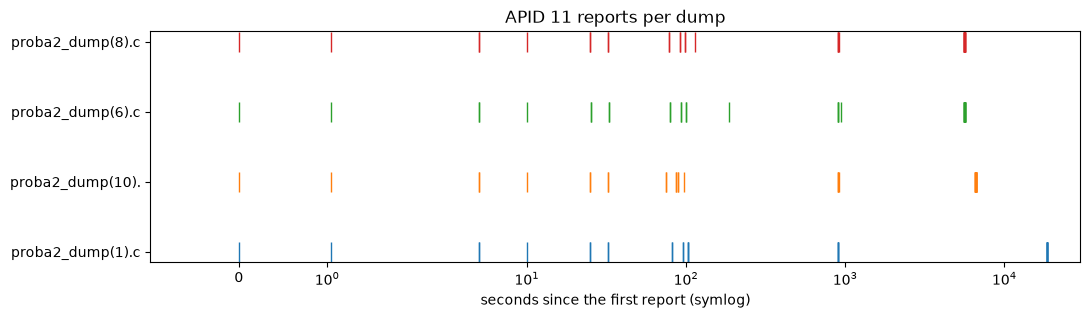

In [7]:
fig, ax = plt.subplots(figsize=(12, 3))
for position, items in enumerate(by_file.values()):
    start = min(t for c in items.values() for t in c.values())
    ax.plot(
        [t - start for c in items.values() for t in c.values()],
        [position] * sum(len(c) for c in items.values()),
        "|",
        markersize=14,
    )
ax.set_yticks(range(len(by_file)), [name[:16] for name in by_file])
ax.set(
    xscale="symlog",
    xlim=(-1, 30000),
    xlabel="seconds since the first report (symlog)",
    title="APID 11 reports per dump",
)
plt.show()

## 4. What we know so far

* APID 11 is the third command target seen (after APID 14 and APID 8): 132 packets, 130 of them PUS service 1 verification reports (1/1 accepted, 1/7 completed,
  never 1/8), 129 with a valid CRC; telecommand packet id `0x180b`. No data of any kind. The other two packets are debris.
* 67 commands in 4 dumps (2025-08-14, 17, 19 and 10-09), 15-18 each, own 14 bit counter 949-2 614.
* They are **steps of a stored procedure**: each step is accepted when the previous one completes, with durations (1, 0, 15, 7, 40-49, 13, 2-8 s) that are the same in every
  dump, and a second half of the same procedure hours later. The spacing, not the commands, is what we see.
* Nothing about the Sun, SWAP or LYRA.